# Inference Pipeline
This notebook loads the trained tagging model and runs inference on a single image.

In [1]:
import os
import sys
import yaml
import torch
from PIL import Image
import matplotlib.pyplot as plt

# Add src to path
sys.path.append(os.path.abspath("src"))

from data.dataset import get_transforms
from models.tagging_model import (
    ResNet50TaggingNN, MobileNetV3TaggingNN, 
    EfficientNetB0TaggingNN, CustomTaggingNN
)

In [2]:
CLASSES = [
    "box", "crate", "barrel", "bottle", "pallet", "rack", "bracket", 
    "lamp", "sign", "wire", "fuse_box", "floor_decal", "fire_extinguisher", 
    "barcode", "wall", "ceiling", "floor", "pillar", "forklift", "bucket", 
    "cone", "cart", "emergency_board", "paper_note", "paper_shortcut"
]

def load_config(config_path):
    with open(config_path, "r") as file:
        return yaml.safe_load(file)

def get_model(model_name, num_classes):
    if model_name == "resnet50": return ResNet50TaggingNN(num_classes=num_classes)
    elif model_name == "mobilenet_v3": return MobileNetV3TaggingNN(num_classes=num_classes)
    elif model_name == "efficientnet_b0": return EfficientNetB0TaggingNN(num_classes=num_classes)
    elif model_name == "custom": return CustomTaggingNN(num_classes=num_classes)
    else: raise ValueError(f"Unknown model: {model_name}")

In [3]:
def predict(image_path, threshold=0.5):
    config_path = "src/config.yaml"
    config = load_config(config_path)
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # 1. Initialize Model
    model = get_model(config["model"]["architecture"], num_classes=len(CLASSES))
    checkpoint_path = os.path.join(config["logging"]["checkpoint_dir"], "best_model.pth")
    
    # 2. Load Weights
    print(f"Loading weights from {checkpoint_path}...")
    model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=False)["model_state_dict"])
    model.to(device)
    model.eval()

    # 3. Process Image
    transform = get_transforms(is_train=False) # Validation transform (no augmentation)
    image = Image.open(image_path).convert("RGB")
    input_tensor = transform(image).unsqueeze(0).to(device) 

    # 4. Inference
    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = torch.sigmoid(logits)[0] 

    # 5. Extract tags above threshold
    detected_tags = []
    for i, prob in enumerate(probabilities):
        if prob > threshold:
            detected_tags.append((CLASSES[i], prob.item()))
            
    detected_tags.sort(key=lambda x: x[1], reverse=True)

    # 6. Display Results
    print(f"\n--- Analysis for: {os.path.basename(image_path)} ---")
    if not detected_tags:
        print(f"No tags detected with confidence > {threshold}")
    else:
        for tag, prob in detected_tags:
            print(f"- {tag.upper()}: {prob*100:.1f}% confidence")

    plt.imshow(image)
    plt.title(", ".join([t[0] for t in detected_tags[:5]]))
    plt.axis("off")
    plt.show()

Loading weights from checkpoints/best_model.pth...

--- Analysis for: warehouse_001938.png ---
- FIRE_EXTINGUISHER: 100.0% confidence
- BOX: 100.0% confidence
- WIRE: 100.0% confidence
- PALLET: 100.0% confidence
- FUSE_BOX: 100.0% confidence
- CEILING: 100.0% confidence
- FLOOR_DECAL: 100.0% confidence
- RACK: 100.0% confidence
- WALL: 100.0% confidence
- LAMP: 99.9% confidence
- SIGN: 99.7% confidence
- PILLAR: 99.5% confidence
- PAPER_NOTE: 99.2% confidence
- FLOOR: 91.8% confidence


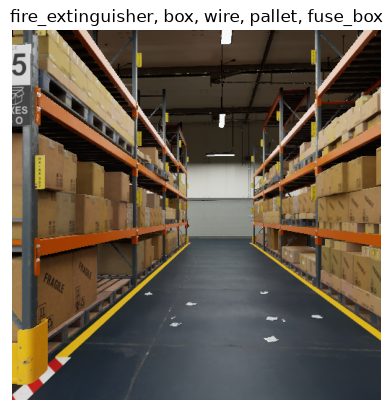

In [4]:
# Try it out on an image
image_path = "data/raw/source_a_synthetic/warehouse_detection_dataset/raw/test/images/warehouse_001938.png"
predict(image_path, threshold=0.5)